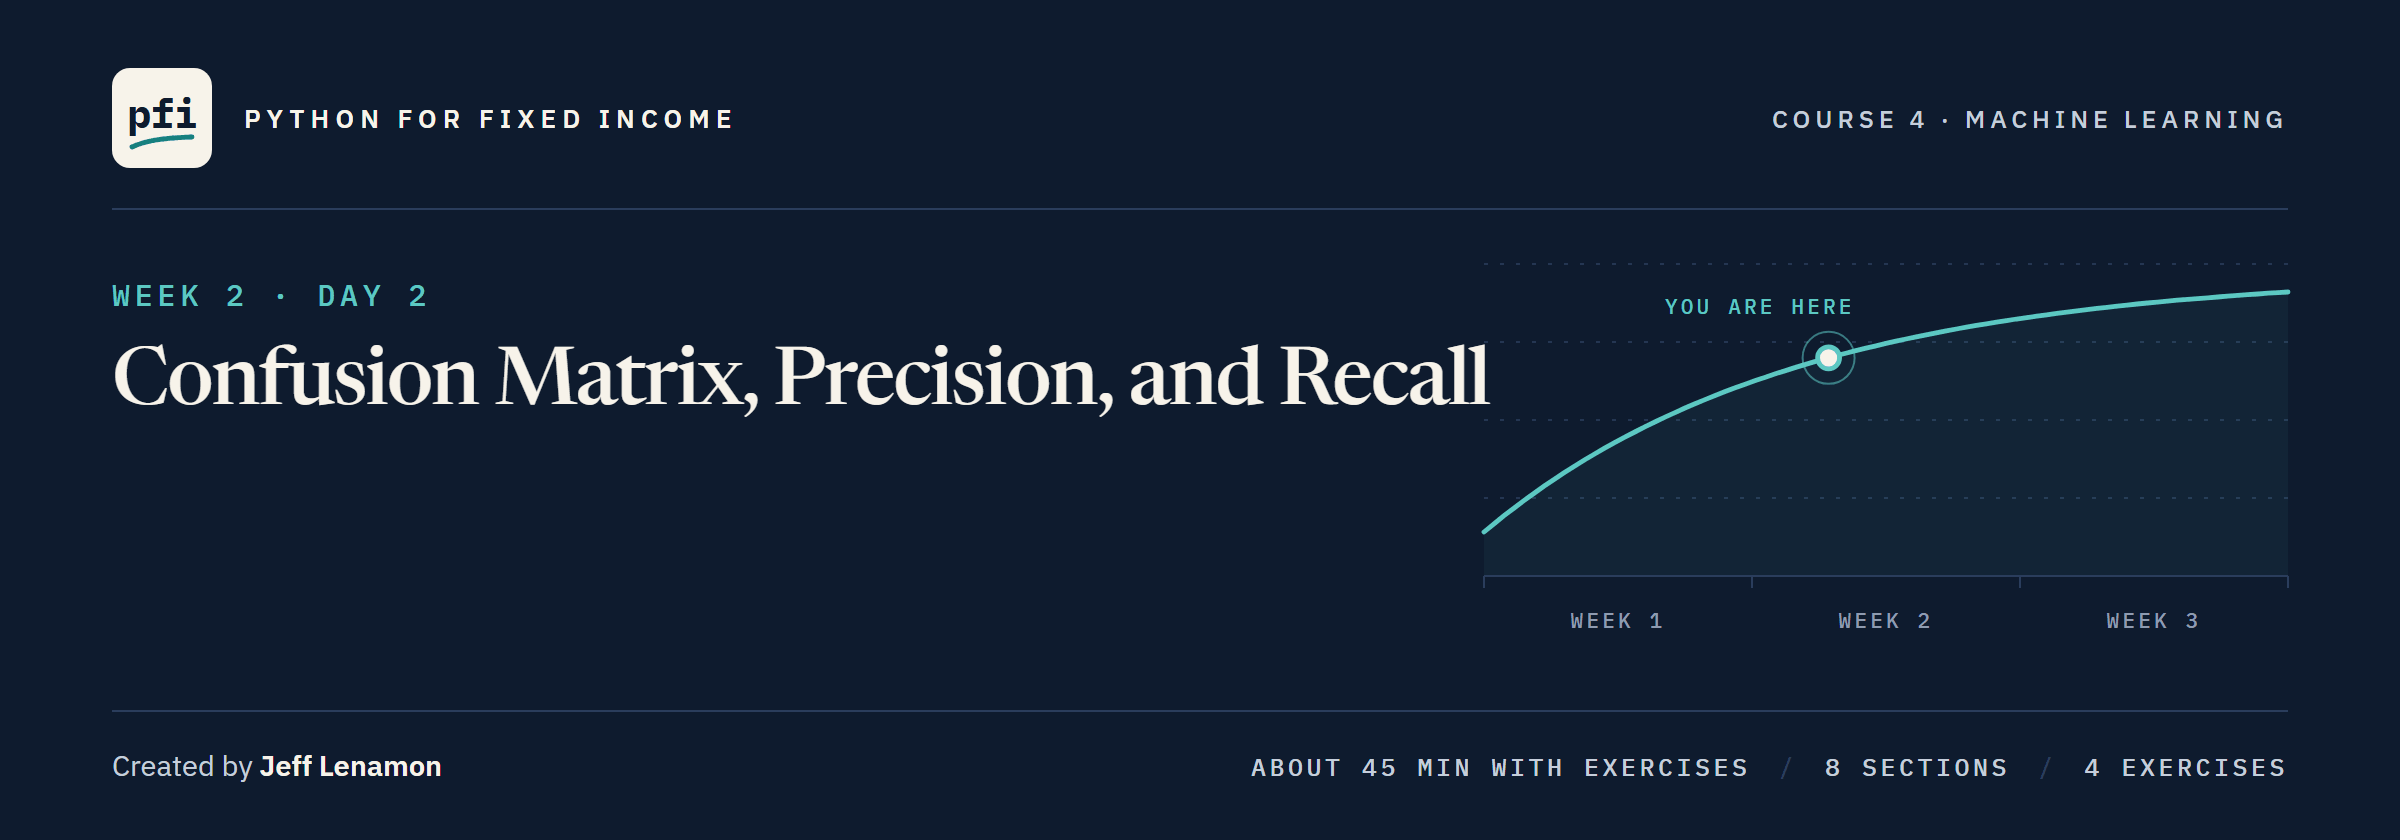

# Confusion Matrix, Precision, and Recall

Week 2, Day 2. Turn the model's probabilities into flags, count what the flags catch and miss, and score them with precision and recall.

**Data:** `credit_card_default.csv`, 30,000 card accounts in Taiwan in 2005: **real**, UCI Machine Learning Repository dataset 350, CC BY 4.0. Citation: Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week2/day2/07_confusion_matrix_precision_and_recall.ipynb)

# Problem Statement

## Business Context

Day 6 ended with a model probability of default in this file for each of 6,000 validation accounts.
A reviewer cannot work through a probability, only through a list of accounts to look at.
A threshold turns each probability into a flag: 1 at or above it, 0 below.
Today's question is how to score that list.
The file is Day 6's: 30,000 real card accounts in Taiwan in 2005, so nothing here carries over to another market or year.
`SEX`, `EDUCATION`, `MARRIAGE` and `AGE` are never features: a model using them would sort people by them, and leaving them out does not make a model neutral, because other columns can carry the same information.
A flag means "flagged at threshold t", never a credit decision about anyone.

## Objectives

Turn probabilities into flags, see why accuracy flatters a model on a one-in-five outcome, read the confusion matrix, write one function that scores flags with precision, recall and F1, and watch what moving the threshold trades.

## Data Dictionary

`credit_card_default.csv`, as on Day 6, one row per account:

1. `ID`: a row label, never a feature
2. `LIMIT_BAL`: the credit limit, NT dollars
3. `PAY_0`, `PAY_2` to `PAY_6`: repayment status, September back to April
4. `BILL_AMT1` to `BILL_AMT6`: the bill, NT dollars
5. `PAY_AMT1` to `PAY_AMT6`: the amount paid, NT dollars
6. `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`: about the person, never features
7. `default payment next month`: 1 if the account defaulted the following month, 0 if not, **the target**

## Your Route Through Day 2

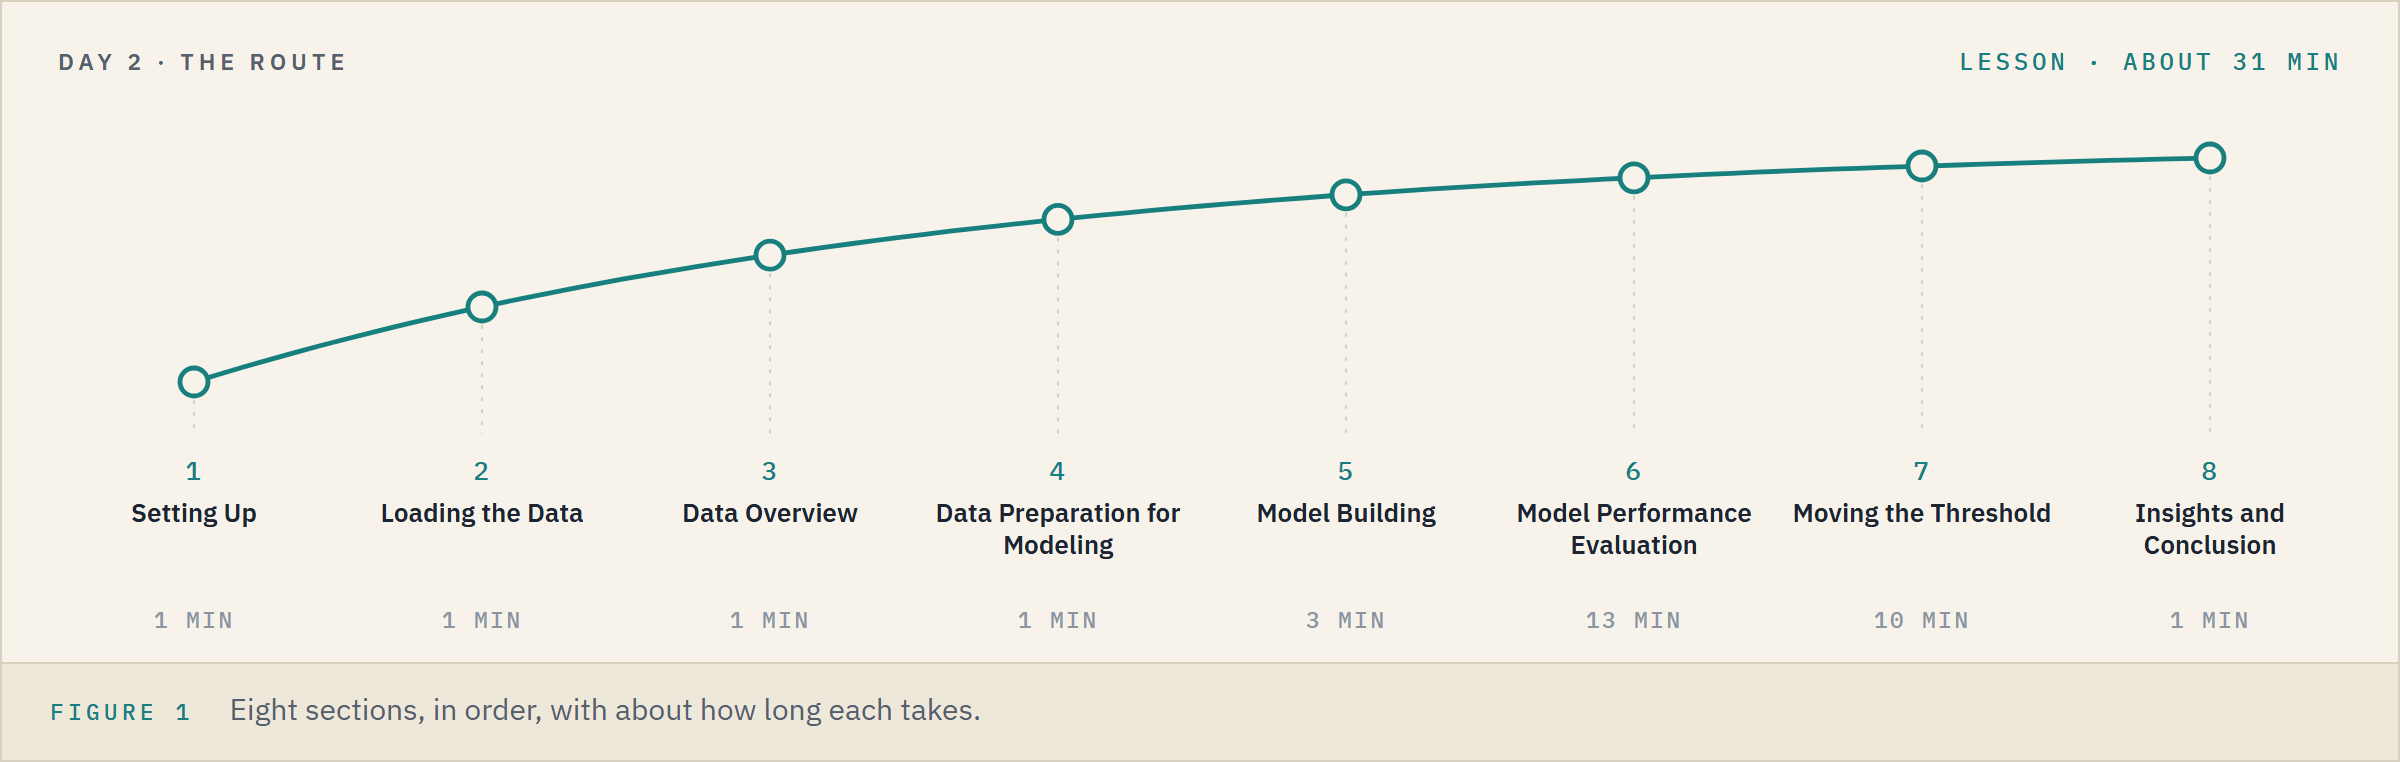

**Time.** About 31 minutes for the lesson, then about 12 for the four exercises.

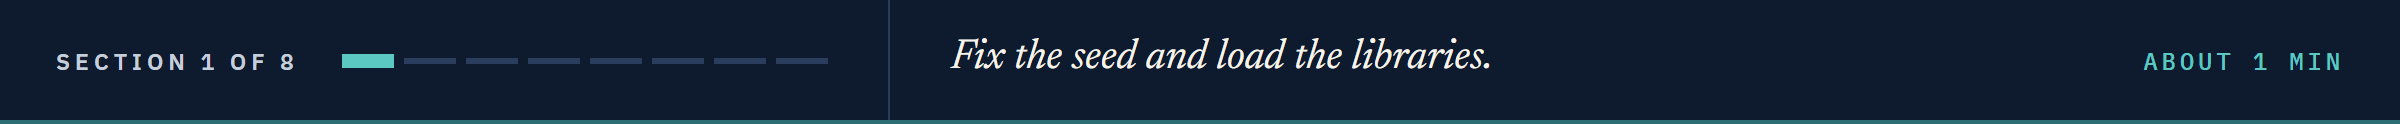

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and the slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split the accounts, fit Day 6's model, and fit two baseline models
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier

# to score flags
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, classification_report

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:,.4f}".format)

# one colour for each of the four kinds of account a confusion matrix counts (named below), the same on Days 7 to 10
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}

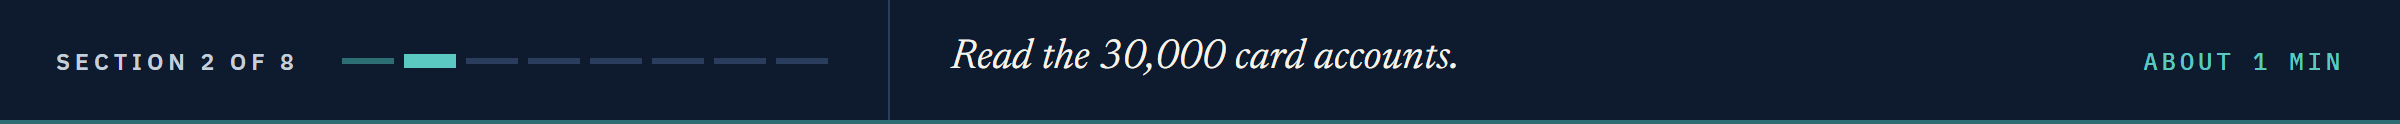

# Loading the Data

## Reading the Card Accounts

In [3]:
# the 30,000 card accounts
card = pd.read_csv(DATA + "credit_card_default.csv")

# the target's name has spaces, so we keep it in a variable
TARGET = "default payment next month"

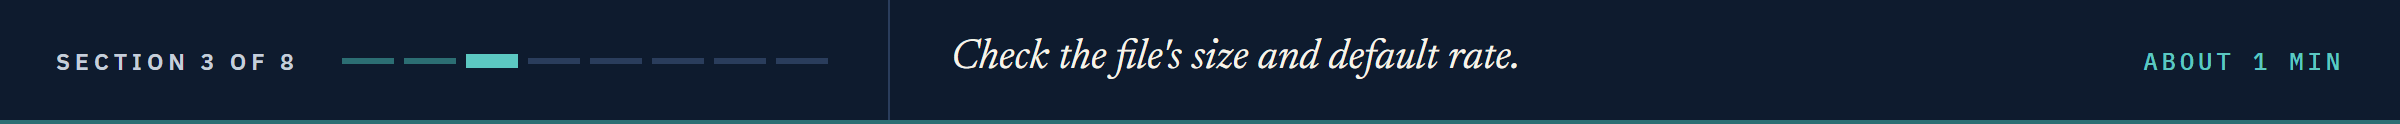

# Data Overview

## Checking the Shape and the Default Rate

In [4]:
# the file's size, and how many accounts defaulted
print(card.shape)
print(card[TARGET].sum(), "accounts defaulted:", round(card[TARGET].mean() * 100, 2), "percent")

(30000, 25)
6636 accounts defaulted: 22.12 percent


30,000 accounts and 25 columns; 6,636 defaulted, 22.12 percent.

**The file is Day 6's and passed Day 6's checks, so we go straight to the split.**

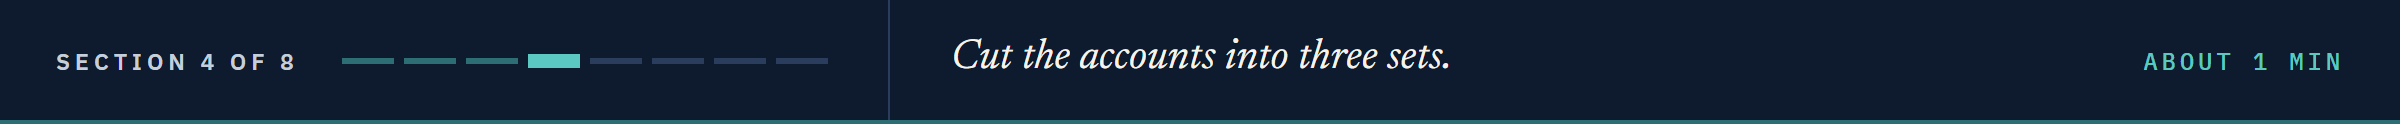

# Data Preparation for Modeling

## Choosing the Features and the Target

In [5]:
# the four columns about the person are never features, and ID is only a row label
PERSON_COLUMNS = ["SEX", "EDUCATION", "MARRIAGE", "AGE"]
FEATURES = [column for column in card.columns if column not in ["ID", TARGET] + PERSON_COLUMNS]
X = card[FEATURES]
y = card[TARGET]
print(len(FEATURES), "features")

19 features


## Splitting Into Training, Validation and Test Accounts

Day 6's two calls with the same seed, so the same accounts land in each part.

In [6]:
# a fifth of the accounts become test accounts, then a quarter of the rest become validation accounts
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=SEED)
print("Training:", len(X_train), " Validation:", len(X_valid), " Test:", len(X_test))
print("Defaults in validation:", y_valid.sum(), " Default rate:", round(y_valid.mean(), 4))

Training: 18000  Validation: 6000  Test: 6000
Defaults in validation: 1327  Default rate: 0.2212


**Fit on training accounts, score on validation accounts; the test accounts stay closed until Day 10.**

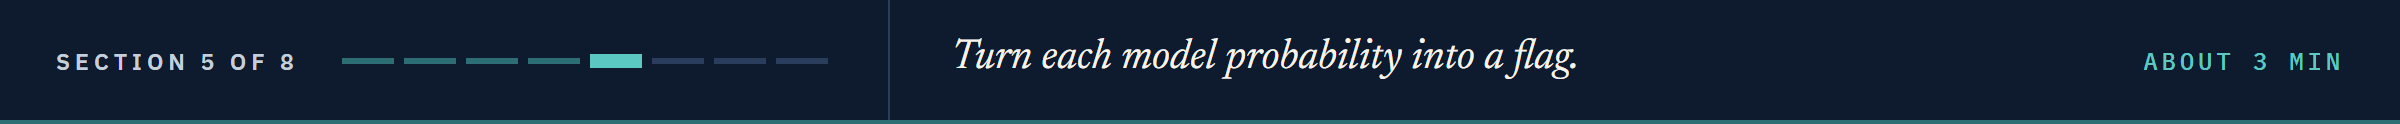

# Model Building

## Day 6's Model, Fitted Again

In [7]:
# scale every column, then fit the logistic regression, as one pipeline: Day 6's model for the week
model = Pipeline([("scale", StandardScaler()), ("logit", LogisticRegression(max_iter=1000))])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('logit', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['LIMIT_BAL','PAY_0','PAY_2',...,'PAY_AMT4','PAY_AMT5','PAY_AMT6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Q. What does the model give each validation account?

In [8]:
# the model probability of default for every validation account
proba_valid = model.predict_proba(X_valid)[:, 1]
print("Median:", round(np.median(proba_valid), 4), " Highest:", round(proba_valid.max(), 4))  # np.median: the middle value

# the first five accounts: what happened, and the model probability
pd.DataFrame({"defaulted": y_valid, "model probability": proba_valid}).head()

Median: 0.1957  Highest: 0.9935


,defaulted,model probability
18316,1,0.2511
1482,0,0.1432
10396,1,0.0557
9360,0,0.1018
18144,0,0.1027


Account 18316 defaulted with a model probability of 0.2511; account 10396 defaulted at 0.0557.

Half the accounts sit below 0.1957, and the highest is 0.9935.

## From a Probability to a Flag

In [9]:
# flag every account whose model probability is at or above 0.5
flag_valid = (proba_valid >= 0.5).astype(int)
print("Flagged:", flag_valid.sum(), "of", len(flag_valid), "accounts,", round(flag_valid.mean() * 100, 2), "percent")

Flagged: 447 of 6000 accounts, 7.45 percent


447 accounts flagged, 7.45 percent, in a file where 22.12 percent defaulted.

`model.predict` flags above 0.5 rather than at or above it; no probability here is exactly 0.5, so the two agree.

In [10]:
# the flags model.predict gives, against ours
print("Same flags as model.predict:", (model.predict(X_valid) == flag_valid).all())

Same flags as model.predict: True


## How Often Is the Flag Right?

Accuracy is the share of accounts whose flag matches what happened; `accuracy_score` computes it.

In [11]:
# the share of validation accounts flagged correctly
print("Accuracy:", round(accuracy_score(y_valid, flag_valid), 4))

Accuracy: 0.8123


**Right on 81 percent of accounts sounds good, until it is set beside a model that reads nothing.**

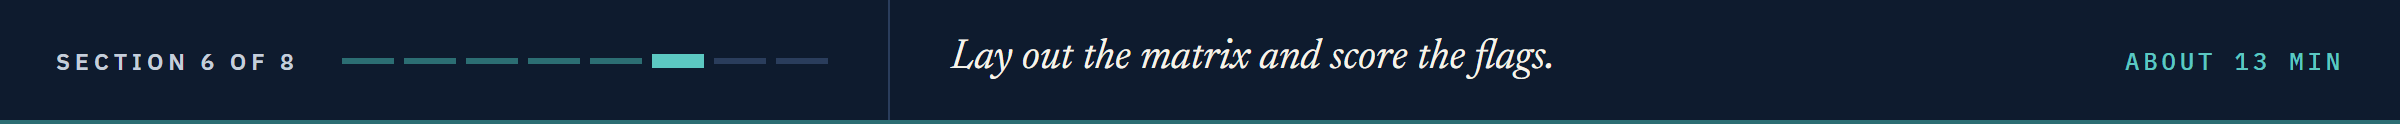

# Model Performance Evaluation

## A Model That Flags Nobody

A baseline model reads nothing, and shows what a real model has to beat.

`DummyClassifier(strategy="most_frequent")` answers every account with the training accounts' most common outcome: 0, paid.

We call it the flag-nobody model, `all_zero` in the code.

**Predict 1**

The flag-nobody model never flags an account.

Write down its accuracy on the 6,000 validation accounts.

In [12]:
# the baseline: fitted on the training accounts, like any model, though it reads no column
all_zero = DummyClassifier(strategy="most_frequent")
all_zero.fit(X_train, y_train)
zero_valid = all_zero.predict(X_valid)
print("Accounts flagged:", zero_valid.sum(), " Accuracy:", round(accuracy_score(y_valid, zero_valid), 4))

Accounts flagged: 0  Accuracy: 0.7788


0.7788: right on every account that paid, wrong on every default.

Day 6's model is 3.35 points above a model that reads nothing.

On a file where most rows are 0, accuracy mostly counts the 0s.

**Accuracy adds two kinds of right and two kinds of wrong into one number; we need them apart.**

## Four Kinds of Account

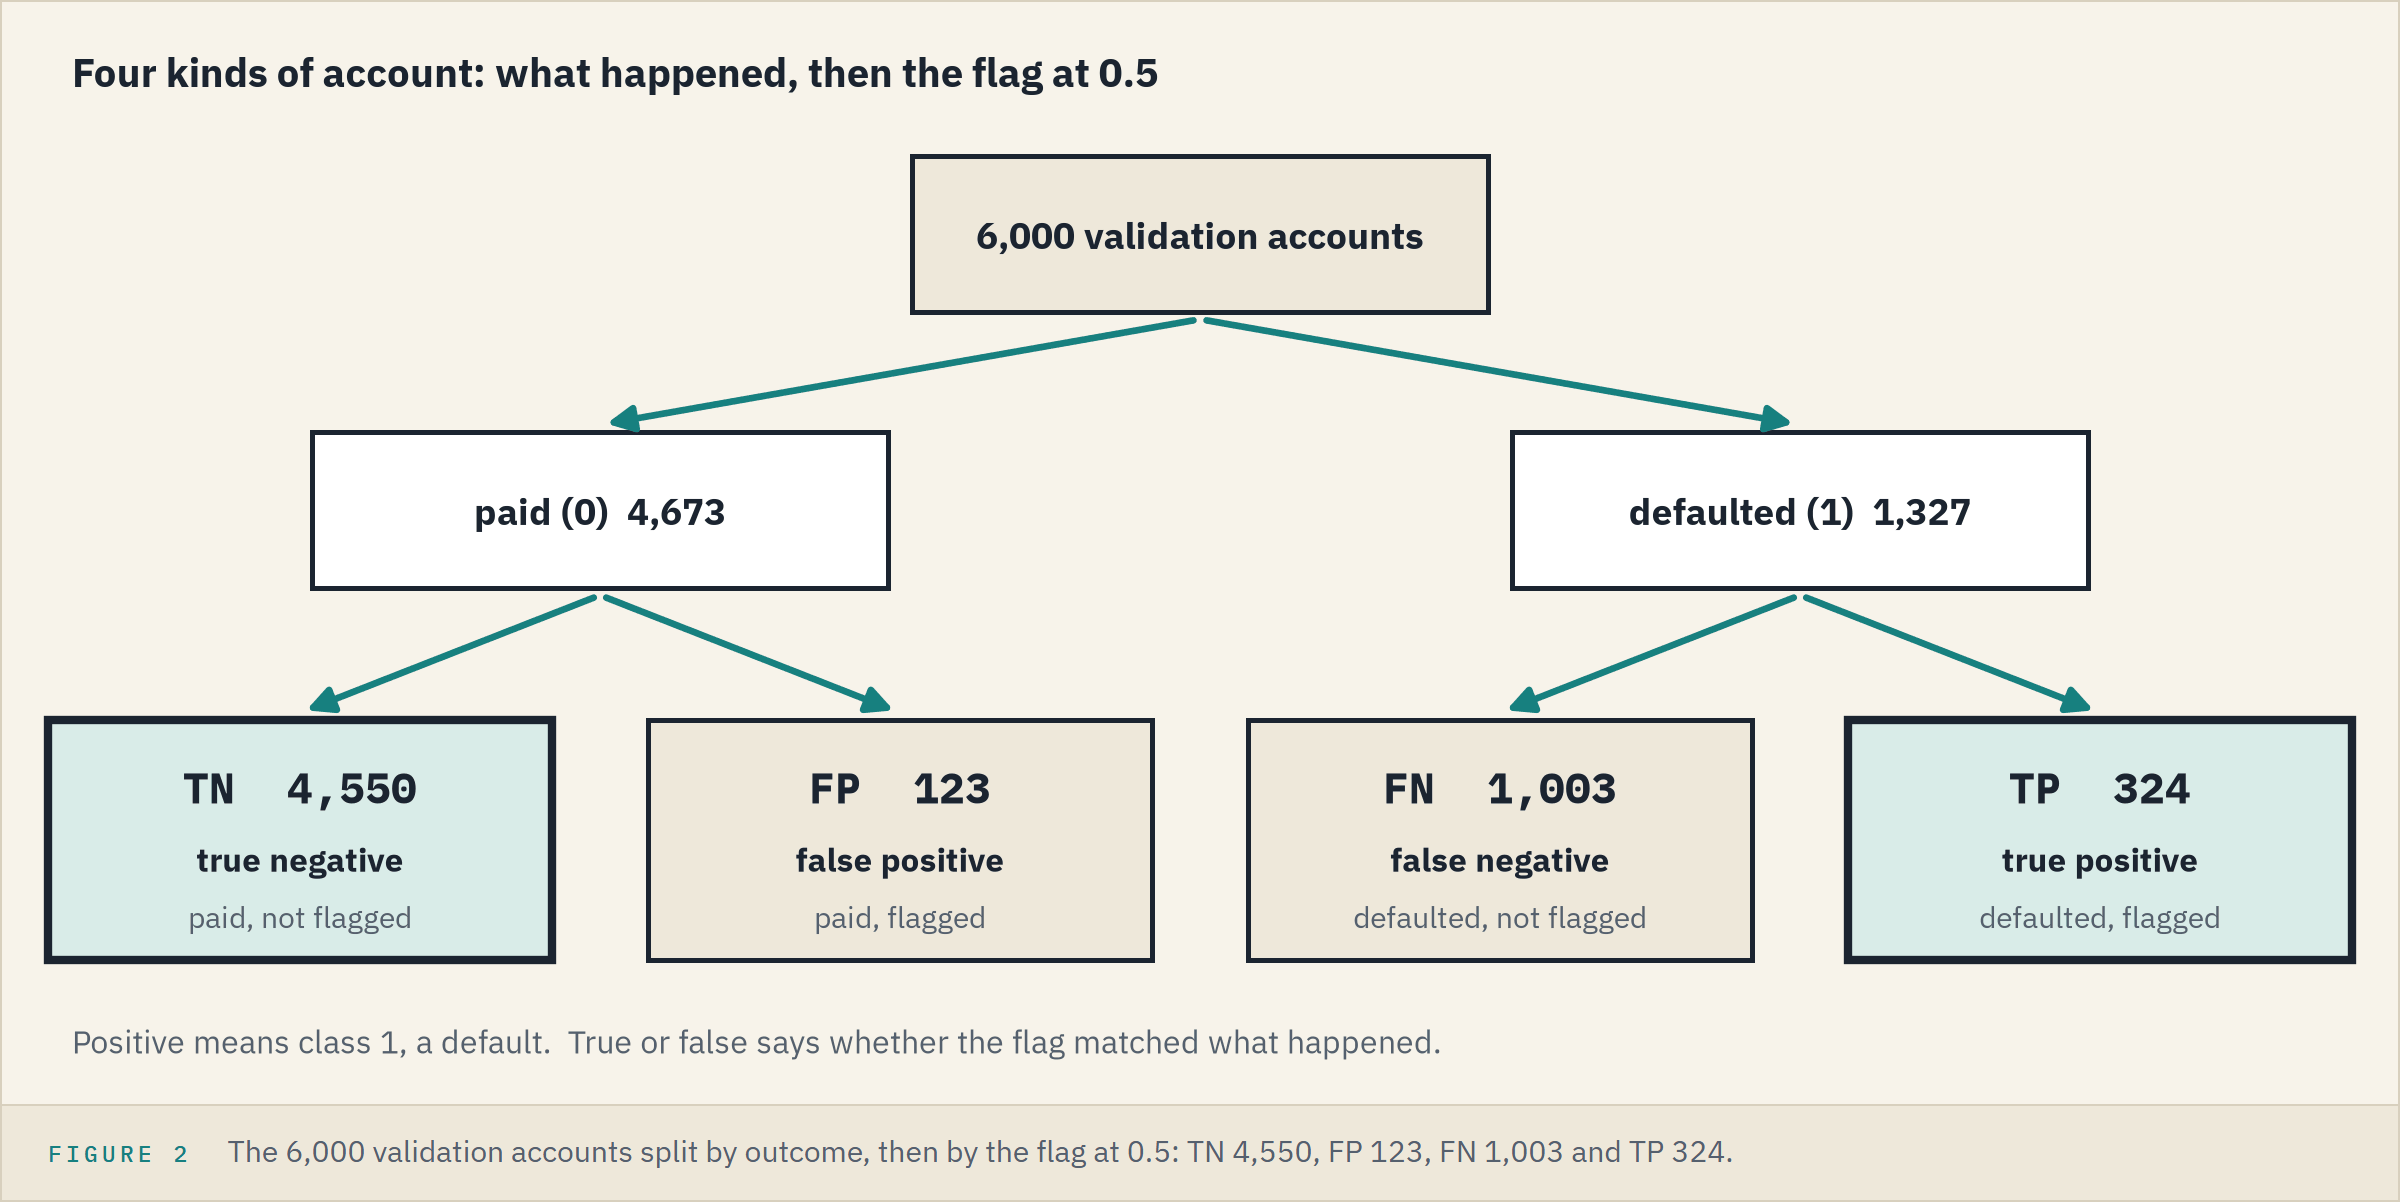

Positive means class 1, a default; true or false says whether the flag matched what happened.

The four kinds: true negatives (TN), false positives (FP), false negatives (FN) and true positives (TP).

The two errors mean different things on a desk:

- A false positive is an account that paid but lands on the list: a review spent for nothing.
- A false negative is a default the list never shows.

## The Confusion Matrix

`confusion_matrix` counts the four kinds in a 2 by 2 table: rows are what happened, columns the flag.

In [13]:
# TN and FP in the top row, FN and TP in the bottom row
confusion_matrix(y_valid, flag_valid)

array([[4550,  123],
       [1003,  324]])

### Putting Labels on the Matrix

Q. How many accounts sit in each row and each column?

In [14]:
# the same counts with names, and a total for every row and column
labelled = pd.DataFrame(confusion_matrix(y_valid, flag_valid), index=["paid (0)", "defaulted (1)"], columns=["not flagged (0)", "flagged (1)"])
labelled["total"] = labelled.sum(axis=1)
labelled.loc["total"] = labelled.sum()
labelled

,not flagged (0),flagged (1),total
paid (0),4550,123,4673
defaulted (1),1003,324,1327
total,5553,447,6000


1,327 accounts defaulted and 447 were flagged, but only 324 are both.

### The Two Models' Matrices

In [15]:
# draw a confusion matrix: each cell in its own colour, with its name, its count and its share of the accounts
def draw_confusion(target, flags, ax, title):
    tn, fp, fn, tp = confusion_matrix(target, flags).ravel()  # .ravel() lays the 2 by 2 out flat: TN, FP, FN, TP
    total = tn + fp + fn + tp
    # :.1% writes a share as a percent with one decimal
    labels = [[f"TN\n{tn:,}\n{tn / total:.1%}", f"FP\n{fp:,}\n{fp / total:.1%}"],
              [f"FN\n{fn:,}\n{fn / total:.1%}", f"TP\n{tp:,}\n{tp / total:.1%}"]]
    # the numbers 0 to 3 pick each cell's colour from the list; annot writes the labels on top (fmt="" as they are), annot_kws sets their size
    sns.heatmap([[0, 1], [2, 3]], cmap=list(CELL_COLOURS.values()), annot=labels, fmt="", cbar=False, ax=ax, annot_kws={"size": 14},
                xticklabels=["not flagged (0)", "flagged (1)"], yticklabels=["paid (0)", "defaulted (1)"])
    ax.set(xlabel="The flag", ylabel="What happened", title=title)  # ax.set sets several of the chart's labels in one call

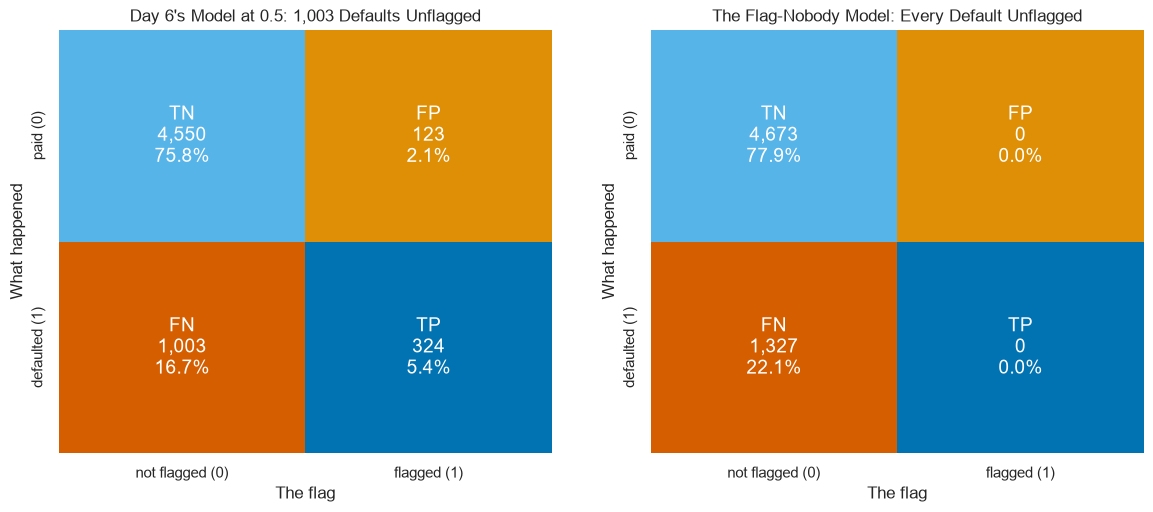

In [16]:
# Day 6's model at 0.5 beside the model that flags nobody
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5.5))
draw_confusion(y_valid, flag_valid, left, "Day 6's Model at 0.5: 1,003 Defaults Unflagged")
draw_confusion(y_valid, zero_valid, right, "The Flag-Nobody Model: Every Default Unflagged")
plt.show()

### Interpretation of the Four Cells

TN is most of either model's accuracy: 75.8 and 77.9 percent of the accounts.

FN, 1,003 defaults left unflagged, is what one accuracy number hid.

The flag-nobody model's right column is empty: with no flag there is no FP and no TP.

## The Matrix Drawn to Scale

A mosaic draws the matrix to scale: each outcome is a column as wide as its share of the accounts, cut by the flag, so every area is a count.

In [17]:
# a mosaic: one bar per outcome, as wide as its share of the accounts, split into not flagged (bottom) and flagged (top)
def draw_mosaic(flags, ax, title):
    counts = confusion_matrix(y_valid, flags)
    shares = confusion_matrix(y_valid, flags, normalize="true")  # each row's counts as shares of that row
    widths = counts.sum(axis=1) / counts.sum()
    lefts = [0, widths[0]]
    # align="edge" starts each bar at its left value; bottom= stacks the flagged bars on the unflagged ones
    bottom = ax.bar(lefts, shares[:, 0], width=widths, align="edge", color=[CELL_COLOURS["TN"], CELL_COLOURS["FN"]], edgecolor="white", linewidth=3)
    top = ax.bar(lefts, shares[:, 1], bottom=shares[:, 0], width=widths, align="edge", color=[CELL_COLOURS["FP"], CELL_COLOURS["TP"]], edgecolor="white", linewidth=3)
    # labels= writes our own words: inside the unflagged bars, and above each column for the flagged ones
    ax.bar_label(bottom, labels=[f"TN {counts[0, 0]:,}", f"FN {counts[1, 0]:,}"], label_type="center", fontsize=13)
    ax.bar_label(top, labels=[f"FP {counts[0, 1]:,}\n{shares[0, 1]:.1%}", f"TP {counts[1, 1]:,}\n{shares[1, 1]:.1%}"], padding=4, fontsize=13)
    ax.set_xticks([widths[0] / 2, widths[0] + widths[1] / 2], [f"paid, {widths[0]:.1%} of accounts", f"defaulted, {widths[1]:.1%}"])
    ax.set(xlim=(0, 1), ylim=(0, 1.14), yticks=[0, 0.25, 0.5, 0.75, 1], ylabel="Share of the column", title=title)
    ax.grid(False)

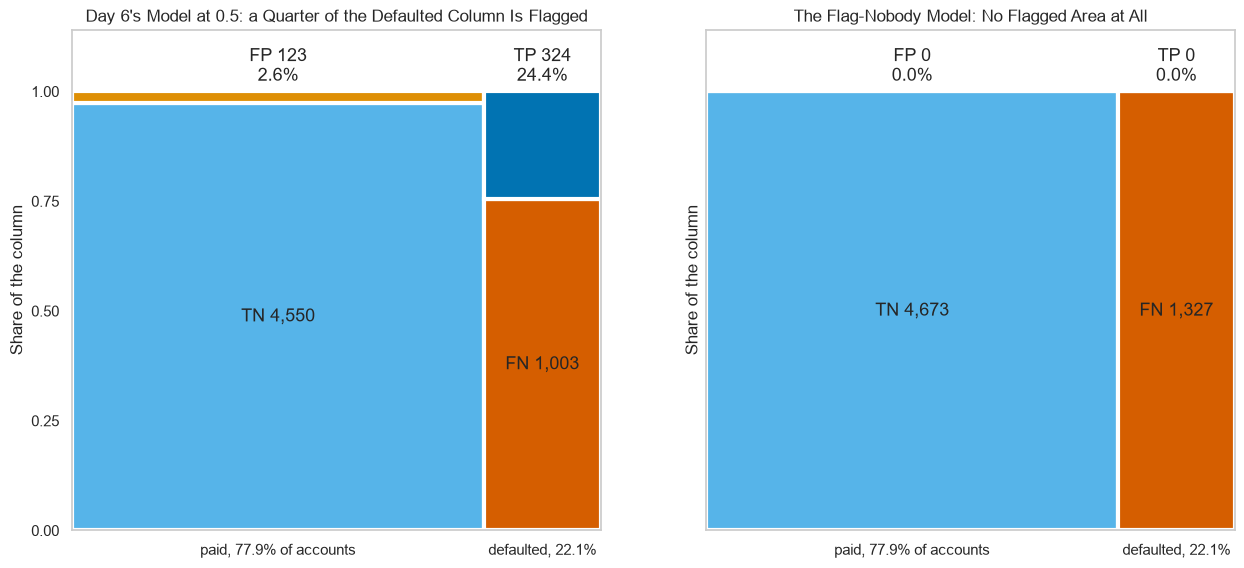

In [18]:
# the two models' matrices, drawn to scale
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
draw_mosaic(flag_valid, left, "Day 6's Model at 0.5: a Quarter of the Defaulted Column Is Flagged")
draw_mosaic(zero_valid, right, "The Flag-Nobody Model: No Flagged Area at All")
plt.show()

In the defaulted column the flagged slice, TP, is 24.4 percent of the height; in the paid column FP is 2.6 percent.

The paid column is wide, so even its thin FP slice holds 123 accounts.

The flag-nobody mosaic is all TN and FN.

**The defaulted column is where a model earns its keep, and two ratios read it.**

## Precision, Recall and F1

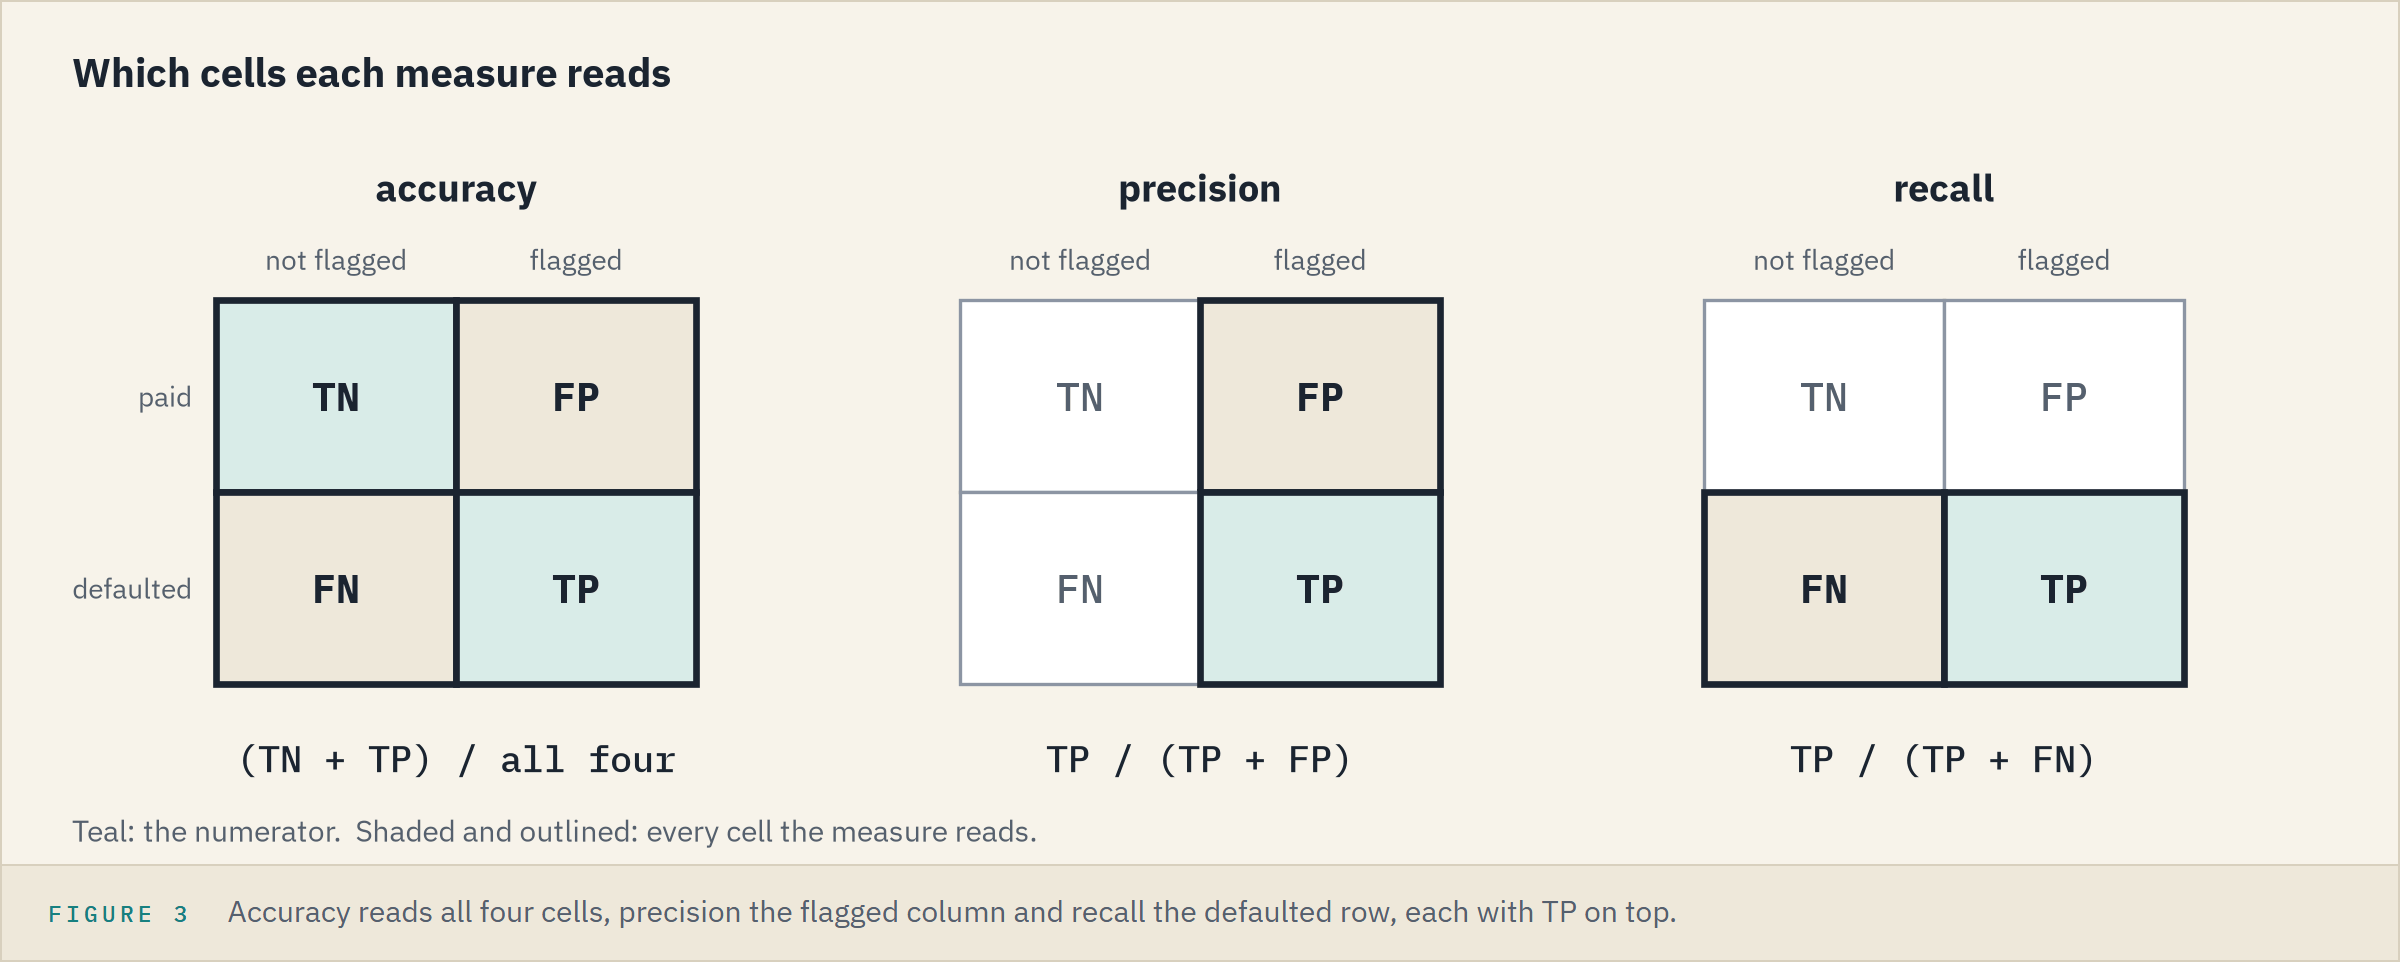

Precision reads the flagged column: of the accounts flagged, the share that defaulted.

Recall reads the defaulted row: of the defaults, the share flagged.

F1 joins them as their harmonic mean, 2 x precision x recall / (precision + recall), which sits near the smaller of the two.

Q. What are the three for the model at 0.5?

In [19]:
# the four counts, then the three measures by hand
tn, fp, fn, tp = confusion_matrix(y_valid, flag_valid).ravel()
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)
print("Precision:", round(precision, 4), " Recall:", round(recall, 4), " F1:", round(f1, 4))
print("Plain mean of the two:", round((precision + recall) / 2, 4))

Precision: 0.7248  Recall: 0.2442  F1: 0.3653
Plain mean of the two: 0.4845


In [20]:
# scikit-learn's three; pos_label=1 says the positive class is 1, the defaults
print("Precision:", round(precision_score(y_valid, flag_valid, pos_label=1), 4))
print("Recall:   ", round(recall_score(y_valid, flag_valid, pos_label=1), 4))
print("F1:       ", round(f1_score(y_valid, flag_valid, pos_label=1), 4))

Precision: 0.7248
Recall:    0.2442
F1:        0.3653


The same three numbers; F1, 0.3653, sits nearer the low recall than the plain mean, 0.4845, does.

### Precision and Recall as 100 Accounts

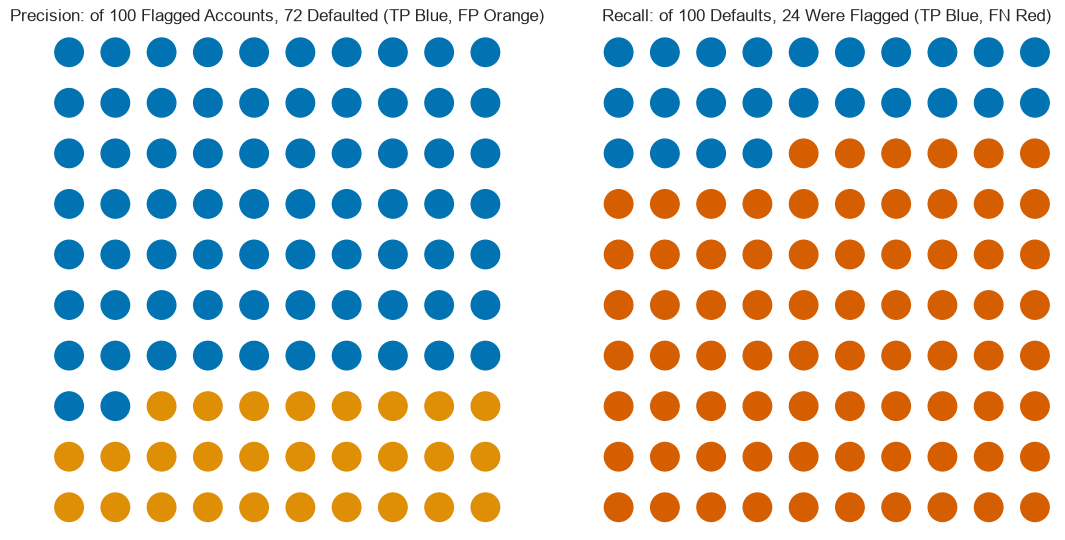

In [21]:
# two icon arrays of 100 dots: 100 flagged accounts, and 100 defaults (% gives the column, // the row)
dots = np.arange(100)
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 6.5))
left.scatter(dots % 10, dots // 10, s=420, color=np.where(dots < round(precision * 100), CELL_COLOURS["TP"], CELL_COLOURS["FP"]))
right.scatter(dots % 10, dots // 10, s=420, color=np.where(dots < round(recall * 100), CELL_COLOURS["TP"], CELL_COLOURS["FN"]))
left.set_title(f"Precision: of 100 Flagged Accounts, {round(precision * 100)} Defaulted (TP Blue, FP Orange)")
right.set_title(f"Recall: of 100 Defaults, {round(recall * 100)} Were Flagged (TP Blue, FN Red)")
for ax in (left, right):
    ax.invert_yaxis()  # fill from the top row down
    ax.set_axis_off()  # no axes or ticks around the dots
plt.show()

### Interpretation of Precision and Recall

A flag at 0.5 is a default about seven times in ten: few false alarms.

About three defaults in four go unflagged: low recall.

## One Function That Scores Any Model

Day 1 scored regressions with `model_performance_regression`; this is its twin for flags, the course's one classification scoring function from here on.

`zero_division=0` gives 0 where a measure would divide by zero, as precision does for a model that flags nobody.

In [22]:
# flag at or above the threshold, then four measures in one row
def model_performance_classification(model, predictors, target, threshold=0.5):
    flags = (model.predict_proba(predictors)[:, 1] >= threshold).astype(int)
    return pd.DataFrame({
        "Accuracy": [accuracy_score(target, flags)],
        "Recall": [recall_score(target, flags, zero_division=0)],
        "Precision": [precision_score(target, flags, zero_division=0)],
        "F1": [f1_score(target, flags, zero_division=0)],
    })

### Training Against Validation

In [23]:
# Day 6's model on the accounts it was fitted on, and on the validation accounts
model_train_perf = model_performance_classification(model, X_train, y_train)
model_valid_perf = model_performance_classification(model, X_valid, y_valid)
train_valid = pd.concat([model_train_perf.T, model_valid_perf.T], axis=1)
train_valid.columns = ["training", "validation"]
train_valid

,training,validation
Accuracy,0.8131,0.8123
Recall,0.2557,0.2442
Precision,0.7179,0.7248
F1,0.3770,0.3653


Every measure moves by about 0.01 or less from training to validation, so the model is not overfitting.

### A Model That Flags Everyone

**Predict 2**

`DummyClassifier(strategy="constant", constant=1)` flags every account.

Write down its precision and its recall on the validation accounts.

In [24]:
# the opposite baseline: every account flagged
all_one = DummyClassifier(strategy="constant", constant=1)
all_one.fit(X_train, y_train)
one_valid_perf = model_performance_classification(all_one, X_valid, y_valid)
one_valid_perf

,Accuracy,Recall,Precision,F1
0,0.2212,1.0000,0.2212,0.3622


Recall 1.0000: flag everyone and every default is caught.

Precision 0.2212, the default rate itself: the flagged column is the whole file.

In [25]:
# the three models on the validation accounts, one column each
zero_valid_perf = model_performance_classification(all_zero, X_valid, y_valid)
models_valid_comp = pd.concat([zero_valid_perf.T, one_valid_perf.T, model_valid_perf.T], axis=1)
models_valid_comp.columns = ["flag nobody", "flag everyone", "Day 6's model"]
models_valid_comp

,flag nobody,flag everyone,Day 6's model
Accuracy,0.7788,0.2212,0.8123
Recall,0.0000,1.0000,0.2442
Precision,0.0000,0.2212,0.7248
F1,0.0000,0.3622,0.3653


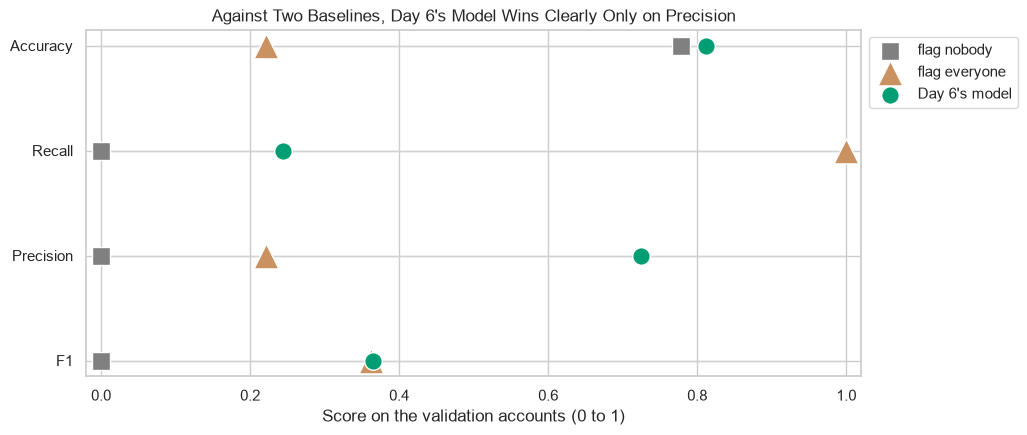

In [26]:
# a Cleveland dot plot: one row per measure, one dot per model, on one 0 to 1 scale
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hlines(models_valid_comp.index, 0, 1, color="lightgray", linewidth=1)
# marker "s" draws a square, "^" a triangle, "o" a circle
for name, marker, size, colour in zip(models_valid_comp.columns, ["s", "^", "o"], [160, 320, 160], ["gray", "#CA9161", "#029E73"]):
    ax.scatter(models_valid_comp[name], models_valid_comp.index, s=size, marker=marker, color=colour, label=name, edgecolor="white", zorder=3)
ax.invert_yaxis()  # Accuracy on the top row
ax.set(xlim=(-0.02, 1.02), xlabel="Score on the validation accounts (0 to 1)", title="Against Two Baselines, Day 6's Model Wins Clearly Only on Precision")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))  # the key just outside the top right corner
plt.show()

Accuracy ranks the flag-nobody model close to Day 6's; recall ranks it last.

The flag-everyone model wins recall outright, and its F1 comes within 0.0031 of Day 6's model.

No single measure tells the story without a baseline beside it.

**The model catches a quarter of the defaults at 0.5, and the 0.5 is ours to move.**

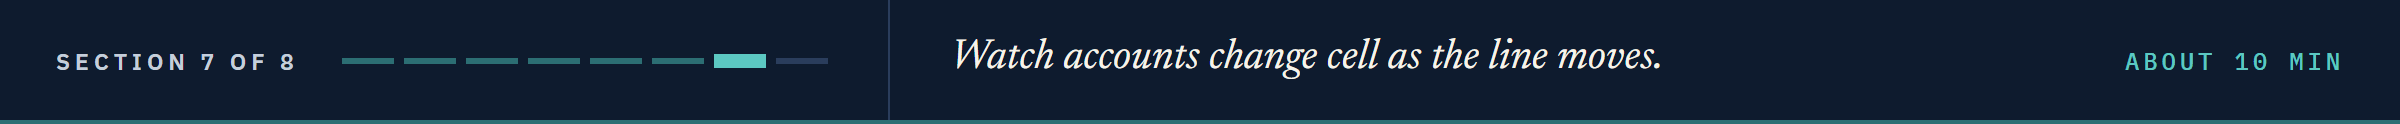

# Moving the Threshold

## What Threshold 0.5 Catches

Q. Where along the model probability does each kind of account sit?

In [27]:
# each account's cell: 2 x what happened + the flag numbers the matrix's cells 0 to 3, row by row
CELL_NAMES = np.array(list(CELL_COLOURS))  # list() of a dictionary gives its keys: TN, FP, FN, TP
cell_valid = CELL_NAMES[2 * y_valid.to_numpy() + flag_valid]  # an array of positions picks one name for each account
pd.Series(cell_valid).value_counts()

TN    4550
FN    1003
TP     324
FP     123
Name: count, dtype: int64

The same four counts as the matrix, now one name per account, so a chart can colour each account by its cell.

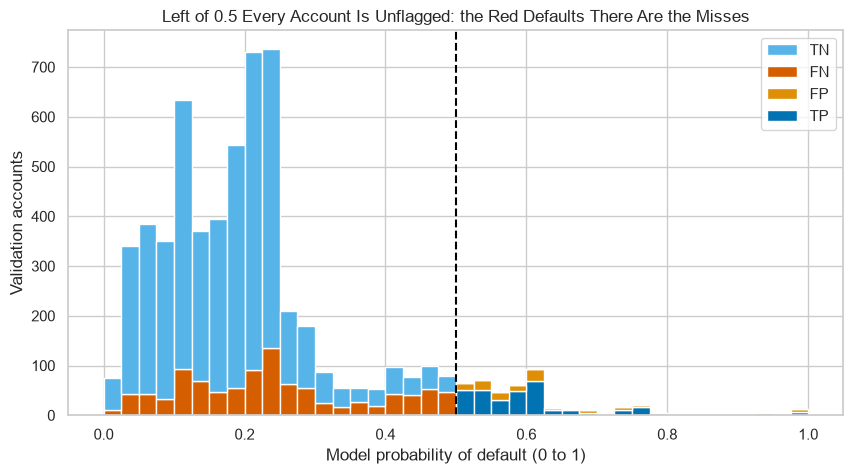

In [28]:
# the model probabilities stacked by cell, with the threshold drawn across
# (multiple="stack" piles each bin's cells on top of one another, in the order hue_order gives)
sns.histplot(x=proba_valid, hue=cell_valid, hue_order=["TN", "FN", "FP", "TP"], palette=CELL_COLOURS, multiple="stack", binwidth=0.025, binrange=(0, 1), alpha=1)
plt.axvline(0.5, color="black", linestyle="--")
plt.xlabel("Model probability of default (0 to 1)")
plt.ylabel("Validation accounts")
plt.title("Left of 0.5 Every Account Is Unflagged: the Red Defaults There Are the Misses")
plt.show()

Left of the line sit TN and the 1,003 FN; right of it, FP and TP.

Move the line left and FN turns into TP, but TN also turns into FP.

**Predict 3**

Precision is 0.7248 at a threshold of 0.5.

Write down precision at 0.7.

In [29]:
# the same model, flagged at 0.7
print("Accounts flagged:", (proba_valid >= 0.7).sum(), " Defaults among them:", y_valid[proba_valid >= 0.7].sum())
model_performance_classification(model, X_valid, y_valid, threshold=0.7)

Accounts flagged: 74  Defaults among them: 50


,Accuracy,Recall,Precision,F1
0,0.7832,0.0377,0.6757,0.0714


0.6757: 74 flagged, 50 of them defaults.

Raising the threshold usually purifies the flags, but it is not a law: here precision fell.

Day 8 asks whether a probability means what it says.

## Your Turn: Move the Threshold

Move the slider and watch accounts change cell.

Find the highest threshold with recall above one half, and note how many accounts it flags.

In [30]:
# your turn: one slider for the threshold
def draw_threshold(threshold=0.5):
    flags = (proba_valid >= threshold).astype(int)
    cells = CELL_NAMES[2 * y_valid.to_numpy() + flags]
    sns.histplot(x=proba_valid, hue=cells, hue_order=["TN", "FN", "FP", "TP"], palette=CELL_COLOURS, multiple="stack", binwidth=0.025, binrange=(0, 1), alpha=1)
    plt.axvline(threshold, color="black", linestyle="--")
    plt.xlabel("Model probability of default (0 to 1)")
    plt.ylabel("Validation accounts")
    plt.title("Right of the Line Is Flagged: the Four Cells at Threshold " + str(round(threshold, 2)))
    plt.show()
    print("Flagged:", flags.sum(), " Recall:", round(recall_score(y_valid, flags), 4), " Precision:", round(precision_score(y_valid, flags), 4))

interact(draw_threshold, threshold=(0.05, 0.95, 0.05));

interactive(children=(FloatSlider(value=0.5, description='threshold', max=0.95, min=0.05, step=0.05), Output()…

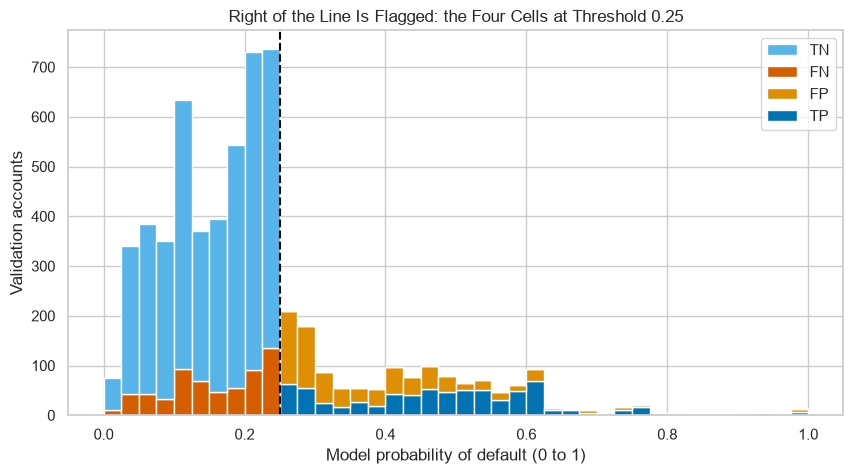

Flagged: 1437  Recall: 0.535  Precision: 0.4941


In [31]:
# the slider set to 0.25, drawn as a still picture (sliders do not run on GitHub)
draw_threshold(threshold=0.25)

At 0.25 the model flags 1,437 accounts, with recall 0.535 and precision 0.4941.

## Four Thresholds Side by Side

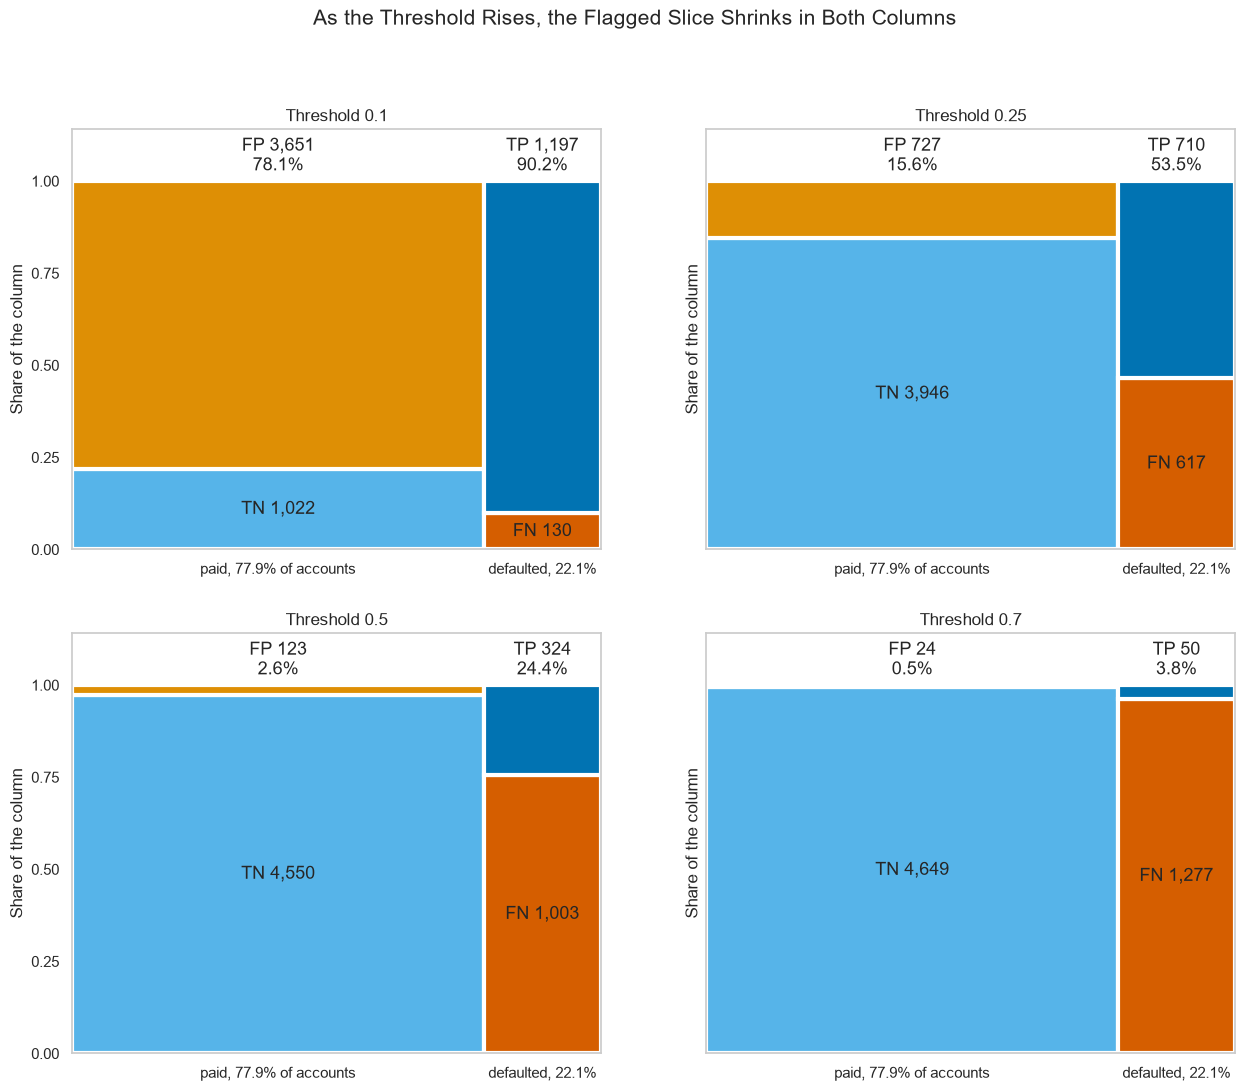

In [32]:
# the matrix drawn to scale at four thresholds, one panel each (axes.flat walks the 2 by 2 panels in reading order)
thresholds = [0.1, 0.25, 0.5, 0.7]
fig, axes = plt.subplots(2, 2, figsize=(15, 12), sharey=True)
for ax, threshold in zip(axes.flat, thresholds):
    draw_mosaic((proba_valid >= threshold).astype(int), ax, "Threshold " + str(threshold))
fig.suptitle("As the Threshold Rises, the Flagged Slice Shrinks in Both Columns", fontsize=15)
plt.show()

In [33]:
# the four measures at each threshold, one row per threshold
by_threshold = pd.concat([model_performance_classification(model, X_valid, y_valid, threshold) for threshold in thresholds])
by_threshold.index = thresholds
by_threshold["plain mean"] = (by_threshold["Recall"] + by_threshold["Precision"]) / 2
by_threshold

,Accuracy,Recall,Precision,F1,plain mean
0.1000,0.3698,0.9020,0.2469,0.3877,0.5745
0.2500,0.7760,0.5350,0.4941,0.5137,0.5146
0.5000,0.8123,0.2442,0.7248,0.3653,0.4845
0.7000,0.7832,0.0377,0.6757,0.0714,0.3567


At 0.1 the model catches 1,197 defaults but flags 3,651 accounts that paid: recall 0.9020, precision 0.2469.

At 0.7 it catches 50 defaults: recall 0.0377.

At 0.1 F1 is 0.3877 where the plain mean is 0.5745: the harmonic mean gives no credit for one good number.

F1 is highest at 0.25 of the four, but F1 counts the two errors as equal, and that is a choice too.

**No threshold wins every column; which error matters more is not in the file.**

## From 0.5 to 0.25, Cell by Cell

In [34]:
# the four counts at each threshold, named
counts_50 = pd.Series(confusion_matrix(y_valid, proba_valid >= 0.5).ravel(), index=CELL_NAMES)
counts_25 = pd.Series(confusion_matrix(y_valid, proba_valid >= 0.25).ravel(), index=CELL_NAMES)
pd.DataFrame({"at 0.5": counts_50, "at 0.25": counts_25, "change": counts_25 - counts_50})

,at 0.5,at 0.25,change
TN,4550,3946,-604
FP,123,727,604
FN,1003,617,-386
TP,324,710,386


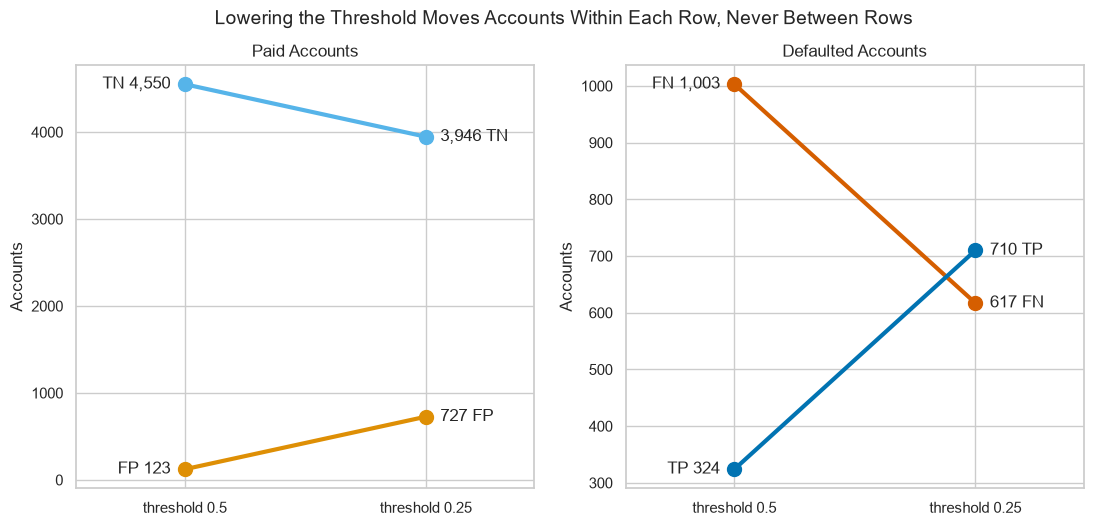

In [35]:
# a slope chart per row of the matrix: each cell's count at 0.5 joined to its count at 0.25
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, pair, row in zip(axes, [["TN", "FP"], ["FN", "TP"]], ["Paid Accounts", "Defaulted Accounts"]):
    for name in pair:
        ax.plot([0, 1], [counts_50[name], counts_25[name]], marker="o", markersize=10, linewidth=3, color=CELL_COLOURS[name])
        ax.text(-0.06, counts_50[name], f"{name} {counts_50[name]:,}", ha="right", va="center", fontsize=12)
        ax.text(1.06, counts_25[name], f"{counts_25[name]:,} {name}", ha="left", va="center", fontsize=12)
    ax.set(xlim=(-0.45, 1.45), xticks=[0, 1], xticklabels=["threshold 0.5", "threshold 0.25"], ylabel="Accounts", title=row)
fig.suptitle("Lowering the Threshold Moves Accounts Within Each Row, Never Between Rows", fontsize=14)
plt.show()

386 defaults move from FN to TP, and 604 accounts that paid move from TN to FP.

Each row's total stays put: a threshold changes the flag, never what happened.

Accuracy falls to 0.7760, below the flag-nobody model's 0.7788, while 386 more defaults are caught.

## Weighing the Two Errors, as an Illustration

Say a missed default counts as w false flags, so a list's total is w x FN + FP.

w is a choice someone makes: no money is attached to these accounts, and no weight here is a rule for lending.

**Predict 4**

Write down the w at which the 0.5 list and the 0.25 list have the same total.

In [36]:
# the total at three weights, for each threshold
for w in [1, 2, 5]:
    print("w =", w, " at 0.5:", w * counts_50["FN"] + counts_50["FP"], " at 0.25:", w * counts_25["FN"] + counts_25["FP"])

w = 1  at 0.5: 1126  at 0.25: 1344
w = 2  at 0.5: 2129  at 0.25: 1961
w = 5  at 0.5: 5138  at 0.25: 3812


In [37]:
# the weight where the two totals meet: the extra false flags over the extra defaults caught
break_even = (counts_25["FP"] - counts_50["FP"]) / (counts_50["FN"] - counts_25["FN"])
print("Break-even weight:", round(break_even, 4))

Break-even weight: 1.5648


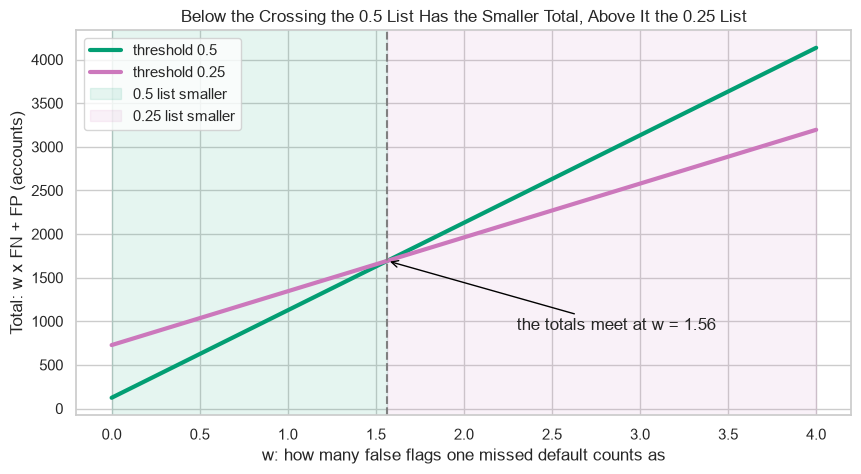

In [38]:
# a break-even chart: each list's total as the weight grows, with each side of the crossing shaded
weights = np.linspace(0, 4, 81)
# green and purple, so no line wears one of the four cells' colours
plt.plot(weights, weights * counts_50["FN"] + counts_50["FP"], linewidth=3, color="C2", label="threshold 0.5")
plt.plot(weights, weights * counts_25["FN"] + counts_25["FP"], linewidth=3, color="C4", label="threshold 0.25")
plt.axvspan(0, break_even, color="C2", alpha=0.1, label="0.5 list smaller")  # axvspan shades between two values of x
plt.axvspan(break_even, 4, color="C4", alpha=0.1, label="0.25 list smaller")
plt.axvline(break_even, color="gray", linestyle="--")
plt.annotate(f"the totals meet at w = {break_even:.2f}", xy=(break_even, break_even * counts_50["FN"] + counts_50["FP"]), xytext=(2.3, 900), arrowprops={"arrowstyle": "->", "color": "black"})
plt.xlabel("w: how many false flags one missed default counts as")
plt.ylabel("Total: w x FN + FP (accounts)")
plt.title("Below the Crossing the 0.5 List Has the Smaller Total, Above It the 0.25 List")
plt.legend(loc="upper left")
plt.show()

Below 1.56 the 0.5 list has the smaller total; above it, the 0.25 list.

The file sets the crossing; the weight comes from outside it.

Day 8 states a recall target instead of a weight.

**Choosing a threshold is choosing a trade; Day 8 draws every threshold at once.**

## `classification_report`, Read Line by Line

Q. What does scikit-learn's own report add to the three numbers?

In [39]:
# precision, recall and F1 for each class, then two averages
print(classification_report(y_valid, flag_valid, digits=4))

              precision    recall  f1-score   support

           0     0.8194    0.9737    0.8899      4673
           1     0.7248    0.2442    0.3653      1327

    accuracy                         0.8123      6000
   macro avg     0.7721    0.6089    0.6276      6000
weighted avg     0.7985    0.8123    0.7739      6000



Row `1` is today's: precision 0.7248, recall 0.2442, F1 0.3653; support is the number of accounts in the class, 1,327.

Row `0` treats paid as the positive class: its recall, 0.9737, is TN / (TN + FP), not the defaults'.

The macro average counts each class the same; the weighted average weighs each by its support, so it leans to class 0, as accuracy does.

**The course reads row `1`.**

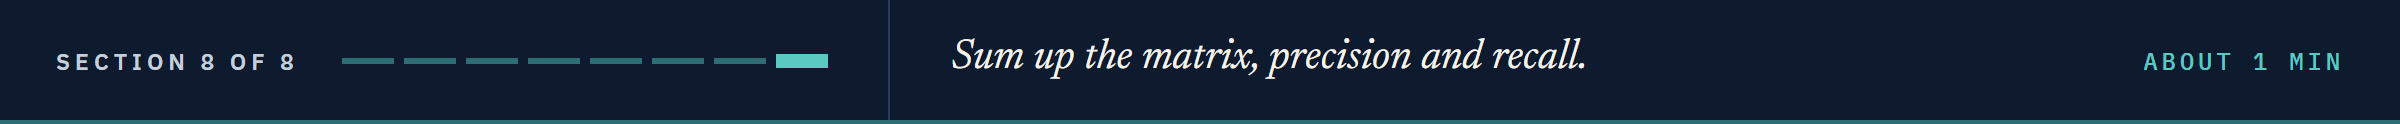

# Insights and Conclusion

Accuracy, 0.8123, is 3.35 points above a model that reads nothing.

At 0.5 the model flags 447 accounts, seven in ten of them defaults, and catches a quarter of the defaults.

Precision reads the flagged column, recall the defaulted row, and F1 stays near the weaker of the two.

Lowering the threshold trades false flags for caught defaults at a rate this file sets: 604 for 386 from 0.5 to 0.25.

The scores describe 6,000 validation accounts in Taiwan in 2005, and no flag is a decision about a person.

**A flag is right in two ways and wrong in two; count all four before trusting one number.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Turn probabilities into flags at a threshold.
* Lay out and read a confusion matrix.
* Compute precision, recall and F1 by hand and with scikit-learn.
* Score any classifier with `model_performance_classification`, against baselines.
* Say what moving the threshold trades, and read `classification_report`.

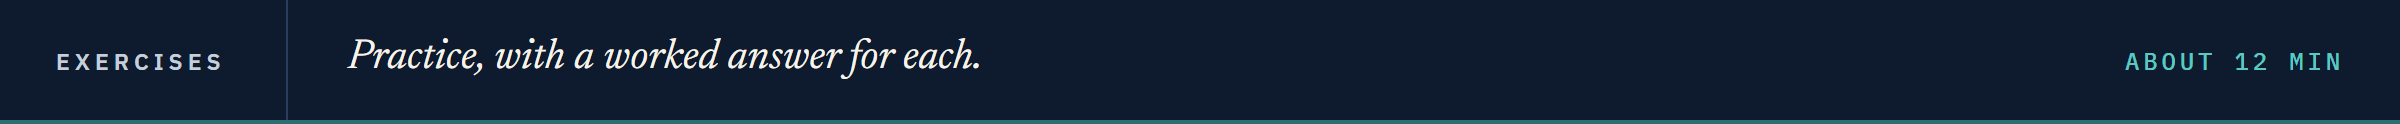

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [40]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**The Matrix at 0.3**

Q. Flag the validation accounts at 0.3. Store the four counts as a list in the order TN, FP, FN, TP in `ex1_counts`.

In [41]:
# your code here
ex1_counts = ...

In [42]:
check("Exercise 1 the four counts at 0.3", ex1_counts, [4220, 453, 733, 594])

Exercise 1 the four counts at 0.3: not attempted yet


### Exercise 2

**September Status Alone**

Q. Fit the same pipeline on `PAY_0` alone, on the training accounts, and score it on the validation accounts with `model_performance_classification`. Store its precision in `ex2_precision` and its recall in `ex2_recall`.

In [43]:
# your code here
ex2_precision = ...
ex2_recall = ...

In [44]:
check("Exercise 2 the precision", ex2_precision, 0.6830870279146142)
check("Exercise 2 the recall", ex2_recall, 0.31348907309721175)

Exercise 2 the precision: not attempted yet
Exercise 2 the recall: not attempted yet


### Exercise 3

**The Flag Rate**

Q. Write a function `flag_rate(flags)` that returns the share of accounts flagged, and test it with three `assert` lines: [0, 1, 1, 0] gives 0.5, [0, 0, 0] gives 0.0, and [1, 1] gives 1.0. Then store `flag_rate(flag_valid)` in `ex3_rate`.

In [45]:
# your code here
ex3_rate = ...

In [46]:
check("Exercise 3 the flag rate at 0.5", ex3_rate, 0.0745)

Exercise 3 the flag rate at 0.5: not attempted yet


### Exercise 4: AI check

**The Recall That Counted the Wrong Class**

You asked an AI assistant for a function that returns precision and recall for the defaults.

It runs, and the recall looks excellent.

Test it, then find the one bug.

In [47]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def default_metrics(target, flags):
    # precision and recall for the defaults, class 1
    return pd.Series({"precision": precision_score(target, flags, pos_label=1),
                      "recall": recall_score(target, flags, pos_label=0)})

print(default_metrics(y_valid, flag_valid))

precision   0.7248
recall      0.9737
dtype: float64


In [48]:
# the check every recall for the defaults passes: TP / (TP + FN), from the matrix
tn, fp, fn, tp = confusion_matrix(y_valid, flag_valid).ravel()
assert np.isclose(default_metrics(y_valid, flag_valid)["recall"], tp / (tp + fn)), "recall for the defaults is TP / (TP + FN)"

AssertionError: recall for the defaults is TP / (TP + FN)

Q. Why does the check fail? Fix the one wrong line and store the fixed function's recall in `ex4_recall`.

In [49]:
# your code here
ex4_recall = ...

In [50]:
check("Exercise 4 the fixed recall", ex4_recall, 0.24415975885455915)

Exercise 4 the fixed recall: not attempted yet


## Congratulations!

You turned probabilities into flags today and learned to score them the way a working data scientist does.
You caught accuracy flattering a model that reads nothing, laid out the four kinds of account, and drew the matrix to scale.
You wrote the course's scoring function, moved the threshold by hand, and weighed the trade between the two errors.
In Day 8 you draw every threshold at once, with ROC and precision-recall curves, and choose one on validation accounts.

[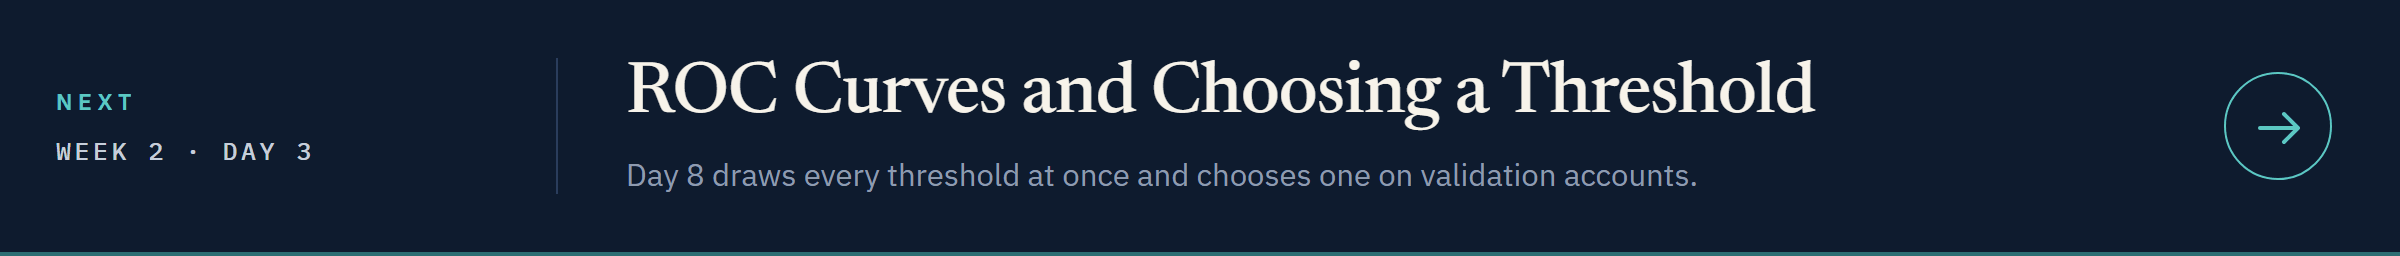](../day3/08_roc_curves_and_choosing_a_threshold.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week2/day3/08_roc_curves_and_choosing_a_threshold.ipynb)